# Crop Recommendation Model

Trains and compares machine-learning models that recommend one of **22 crops** from soil and weather conditions (N, P, K, temperature, humidity, pH, rainfall), then saves the best one as `users/crop1.pkl` for the Django app.

> **Note:** the original training notebook was not part of the project report, so this notebook is a **rebuild** of that step using the public *Crop Recommendation* dataset (2,200 rows, 22 crops). The numbers below are measured here and are not copied from the report.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("../data/crop_recommendation.csv")
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (2200, 8)
Missing values: 0


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56


In [4]:
counts = df["label"].value_counts()
print("Balanced dataset" if counts.nunique() == 1 else "Unbalanced dataset",
      f"- {counts.size} crops, {counts.iloc[0]} samples each" if counts.nunique() == 1 else "")
counts.head(5)

Balanced dataset - 22 crops, 100 samples each


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
Name: count, dtype: int64

## 2. Explore

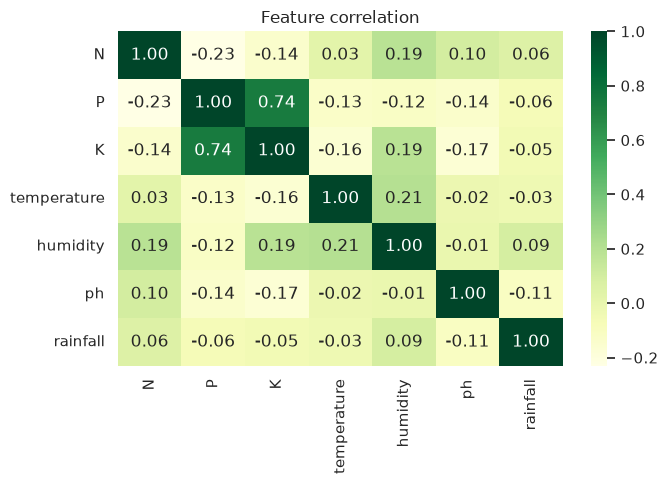

In [5]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="YlGn", ax=ax)
ax.set_title("Feature correlation")
plt.tight_layout(); plt.show()

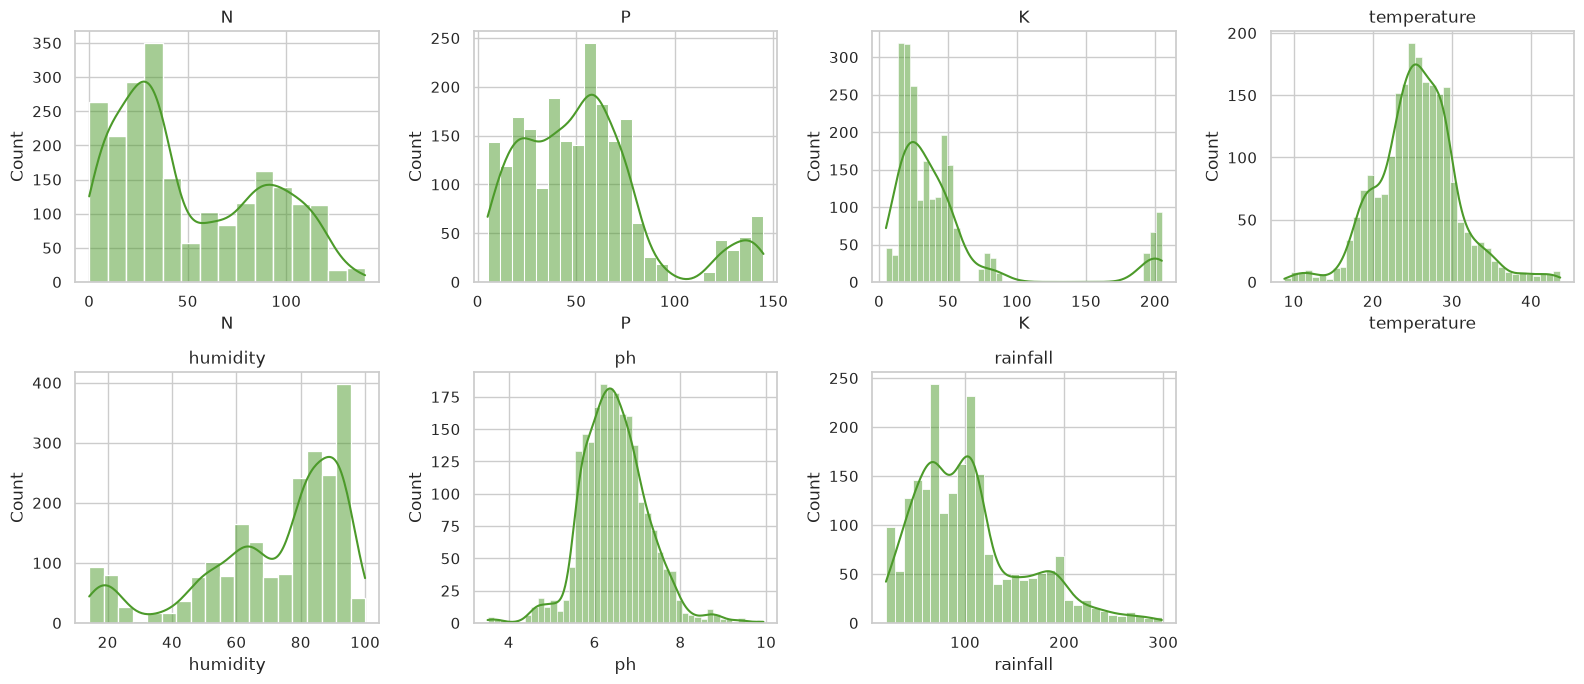

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="#4c9a2a")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 3. Prepare the data

The Django view maps the model's integer output to a crop name using an alphabetical list (`Apple`, `Banana`, `BlackGram`, ...). `LabelEncoder` also orders classes alphabetically, so we check that the two lists line up.

In [7]:
le = LabelEncoder()
y = le.fit_transform(df["label"])
X = df[features].values

# Same list as in users/views.py (Deploy_8)
view_crops = ['Apple', 'Banana', 'BlackGram', 'Chickpea', 'Coconut', 'Coffee', 'Cotton', 'Grapes', 'Jute',
              'KidneyBeans', 'Lentil', 'Maize', 'Mango', 'MothBeans', 'MungBean', 'Musk melon', 'Orange',
              'Papaya', 'Pigeonpeas', 'Pomegranate', 'Rice', 'Watermelon']
norm = lambda s: s.lower().replace(" ", "")
assert [norm(c) for c in view_crops] == [norm(c) for c in le.classes_], "class order differs from the Django view"
print("Class order matches the Django view:", len(le.classes_), "crops")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

Class order matches the Django view: 22 crops
Train: (1760, 7) Test: (440, 7)


## 4. Compare models

The Django view passes raw feature values to `model.predict(...)`, so every model is wrapped in a pipeline that includes its own preprocessing (scaling for the neural network).

In [8]:
models = {
    "MLP Classifier": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=RANDOM_STATE)),
    "Bagging Classifier": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    t0 = time.time()
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    rows.append({"Model": name,
                 "CV accuracy (mean)": round(cv_scores.mean(), 4),
                 "CV std": round(cv_scores.std(), 4),
                 "Test accuracy": round(test_acc, 4),
                 "Seconds": round(time.time() - t0, 1)})

results = pd.DataFrame(rows).sort_values("Test accuracy", ascending=False).reset_index(drop=True)
results

,Model,CV accuracy (mean),CV std,Test accuracy,Seconds
0,Random Forest,0.9943,0.0048,0.9955,3.7
1,MLP Classifier,0.9858,0.0036,0.9909,17.7
2,Bagging Classifier,0.9920,0.0066,0.9909,4.1


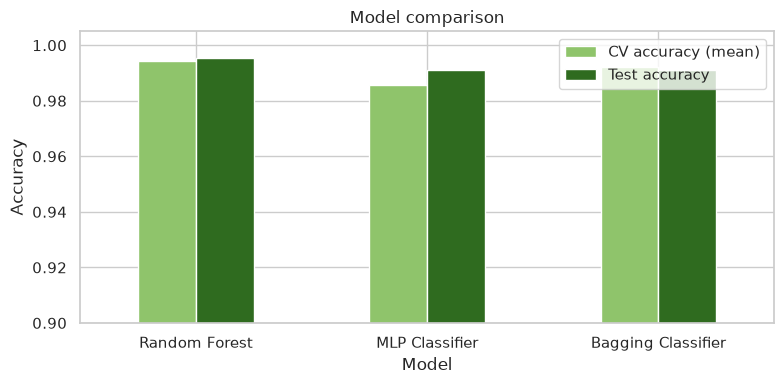

In [9]:
ax = results.set_index("Model")[["CV accuracy (mean)", "Test accuracy"]].plot.bar(
    figsize=(8, 4), color=["#8fc46b", "#2f6b1f"], rot=0)
ax.set_ylim(0.9, 1.005); ax.set_ylabel("Accuracy"); ax.set_title("Model comparison")
plt.tight_layout(); plt.show()

## 5. Evaluate the best model

In [10]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name)

pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=le.classes_, digits=3))

Best model: Random Forest
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.950     0.974        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000     1.000     1.000        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000        20
 

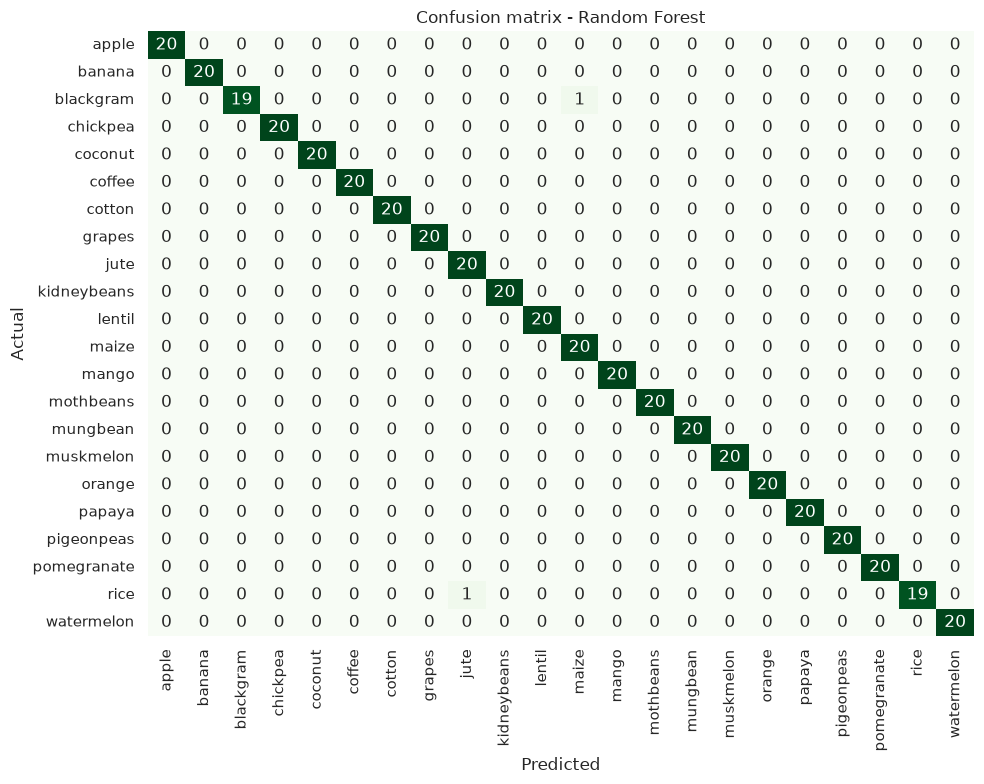

In [11]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix - {best_name}")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

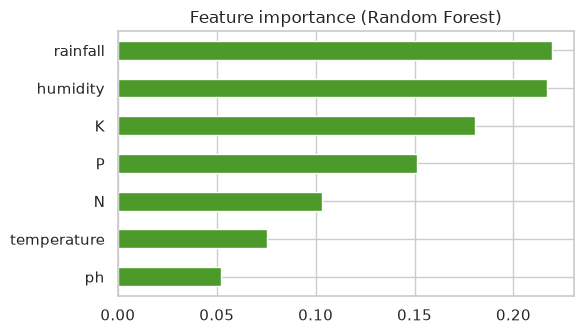

In [12]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
ax = imp.plot.barh(figsize=(6, 3.5), color="#4c9a2a")
ax.set_title("Feature importance (Random Forest)")
plt.tight_layout(); plt.show()

## 6. Save the model for the Django app

In [13]:
# Refit the chosen model on ALL the data before saving
final_model = models[best_name].fit(X, y)
joblib.dump(final_model, "../users/crop1.pkl")

# Sanity check: reload and predict the way users/views.py does
loaded = joblib.load("../users/crop1.pkl")
sample = np.array([[90, 42, 43, 20.9, 82.0, 6.5, 202.9]])   # a typical rice row
idx = loaded.predict(sample)[0]
print("Predicted crop:", view_crops[idx])

Predicted crop: Rice
